# PHÂN TÍCH VÀ TRỰC QUAN HÓA DỮ LIỆU E-COMMERCE

**Dataset:** E-Commerce Customer Behavior & Sales 2020–2026

Notebook thực hiện phân tích và trực quan hóa dữ liệu kinh doanh với nội dung:

1. Doanh thu theo tháng trong 6 năm: xu hướng và tính thời vụ.

Dữ liệu sử dụng được lấy từ thư mục `data/cleaned`, đã qua quá trình tiền xử lý và làm sạch.

## 1. CHUẨN BỊ MÔI TRƯỜNG

Import các thư viện cần thiết để đọc, xử lý và trực quan hóa dữ liệu.

In [1]:
# Import các thư viện
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Thiết lập hiển thị
pd.set_option('display.max_columns', None)
pd.set_option('display.float_format', '{:,.2f}'.format)

sns.set_theme(style='whitegrid')
plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['axes.unicode_minus'] = False

print("Các thư viện đã được import thành công!")

Các thư viện đã được import thành công!


In [2]:
# Tạo thư mục lưu các biểu đồ kết quả
import os

os.makedirs('../report', exist_ok=True)

print("Đã tạo thư mục report!")

Đã tạo thư mục report!


## 2. ĐỌC DỮ LIỆU ĐÃ LÀM SẠCH

Sử dụng các bộ dữ liệu đã được tiền xử lý trong thư mục `data/cleaned` để thực hiện phân tích.

In [3]:
# Đọc dữ liệu đã làm sạch
monthly_revenue = pd.read_csv('../data/cleaned/monthly_revenue_cleaned.csv')

print("Đọc dữ liệu thành công!")
print("Monthly Revenue:", monthly_revenue.shape)

Đọc dữ liệu thành công!
Monthly Revenue: (75, 10)


## 2.1. Xác định dữ liệu sử dụng

- `monthly_revenue`: Dữ liệu doanh thu tổng hợp theo tháng, phục vụ phân tích xu hướng và tính thời vụ.

Các bảng dữ liệu được sử dụng theo đúng mục đích của từng câu hỏi.

# 4. CÂU 2. DOANH THU THEO THÁNG TRONG 6 NĂM: XU HƯỚNG VÀ TÍNH THỜI VỤ

Mục tiêu: Phân tích sự biến động doanh thu theo từng tháng trong giai đoạn nghiên cứu, qua đó nhận diện xu hướng tăng trưởng và các đặc điểm thời vụ của hoạt động kinh doanh.

In [4]:
# Kiểm tra phạm vi thời gian và dữ liệu doanh thu
print("Số dòng dữ liệu:", len(monthly_revenue))
print("Các năm:", sorted(monthly_revenue['year'].unique()))
print("Các tháng:", sorted(monthly_revenue['month'].unique()))

print("\nThông tin doanh thu:")
display(monthly_revenue[['year', 'month', 'revenue_usd']].head(10))

print("\nSố giá trị bị thiếu:")
print(monthly_revenue[['year', 'month', 'revenue_usd']].isna().sum())

Số dòng dữ liệu: 75
Các năm: [np.int64(2020), np.int64(2021), np.int64(2022), np.int64(2023), np.int64(2024), np.int64(2025), np.int64(2026)]
Các tháng: [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10), np.int64(11), np.int64(12)]

Thông tin doanh thu:


,year,month,revenue_usd
0,2020,1,"35,415.25"
1,2020,2,"34,304.78"
2,2020,3,"32,642.23"
3,2020,4,"34,865.39"
4,2020,5,"38,625.73"
5,2020,6,"31,689.22"
6,2020,7,"31,542.99"
7,2020,8,"35,804.39"
8,2020,9,"34,467.90"
9,2020,10,"31,217.93"



Số giá trị bị thiếu:
year           0
month          0
revenue_usd    0
dtype: int64


In [5]:
# Sắp xếp dữ liệu theo năm và tháng
monthly_revenue = monthly_revenue.sort_values(
    by=['year', 'month']
).reset_index(drop=True)

# Kiểm tra thời điểm bắt đầu và kết thúc
print("Tháng đầu tiên:")
display(monthly_revenue[['year', 'month', 'revenue_usd']].head(1))

print("Tháng cuối cùng:")
display(monthly_revenue[['year', 'month', 'revenue_usd']].tail(1))

# Kiểm tra số tháng theo từng năm
print("Số tháng dữ liệu theo năm:")
display(monthly_revenue.groupby('year')['month'].count())

Tháng đầu tiên:


,year,month,revenue_usd
0,2020,1,"35,415.25"


Tháng cuối cùng:


,year,month,revenue_usd
74,2026,3,"32,872.17"


Số tháng dữ liệu theo năm:


year
2020    12
2021    12
2022    12
2023    12
2024    12
2025    12
2026     3
Name: month, dtype: int64

## 4.1. Phân tích xu hướng doanh thu theo thời gian

Sử dụng biểu đồ đường (Line Chart) để thể hiện sự biến động doanh thu qua từng tháng trong giai đoạn từ tháng 01/2020 đến tháng 03/2026.

Biểu đồ giúp quan sát xu hướng tăng trưởng, suy giảm và những biến động đáng chú ý của doanh thu theo thời gian.

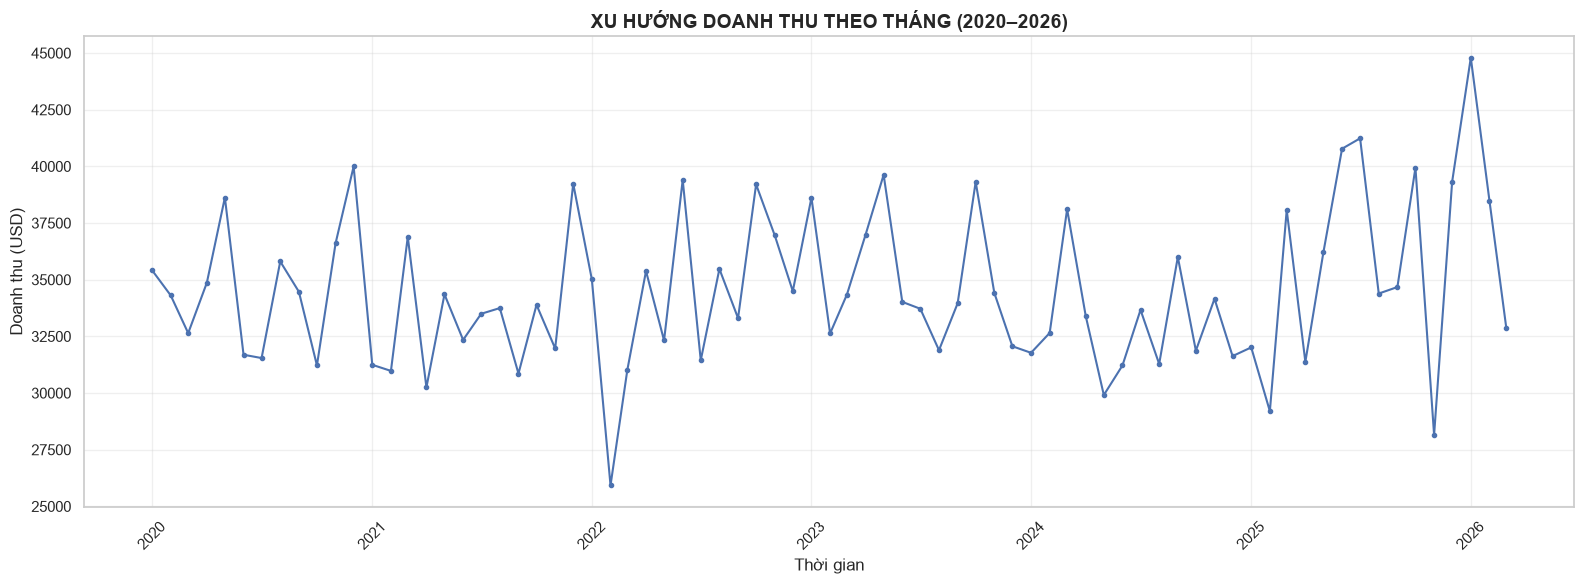

In [6]:
# Tạo cột thời gian từ năm và tháng
monthly_revenue['date'] = pd.to_datetime(
    monthly_revenue[['year', 'month']].assign(day=1)
)

# Vẽ biểu đồ doanh thu theo tháng
plt.figure(figsize=(16, 6))

plt.plot(
    monthly_revenue['date'],
    monthly_revenue['revenue_usd'],
    marker='o',
    markersize=3,
    linewidth=1.5
)

plt.title(
    'XU HƯỚNG DOANH THU THEO THÁNG (2020–2026)',
    fontsize=14,
    fontweight='bold'
)
plt.xlabel('Thời gian')
plt.ylabel('Doanh thu (USD)')
plt.grid(True, alpha=0.3)
plt.xticks(rotation=45)

plt.tight_layout()
plt.savefig(
    '../report/monthly_revenue_trend.png',
    dpi=300,
    bbox_inches='tight'
)
plt.show()

### Nhận xét

- Doanh thu có sự biến động đáng kể giữa các tháng, chủ yếu dao động trong khoảng 30.000–40.000 USD.
- Trong năm 2022, doanh thu xuất hiện mức giảm sâu xuống khoảng 26.000 USD, thấp nhất trên toàn bộ biểu đồ.
- Năm 2025 có nhiều đợt tăng mạnh (tháng 6 và tháng 7 đều vượt 40.000 USD); mức doanh thu cao nhất toàn giai đoạn là gần 45.000 USD vào tháng 1/2026.
- Đầu năm 2026, doanh thu tiếp tục biến động, chưa cho thấy xu hướng tăng trưởng ổn định.
- Nhìn chung, doanh thu chưa thể hiện xu hướng tăng hoặc giảm liên tục trong toàn giai đoạn mà chủ yếu biến động theo từng tháng.

### Kết luận

Hoạt động kinh doanh có doanh thu tương đối lớn nhưng biến động theo thời gian khá rõ rệt. Một số giai đoạn ghi nhận mức tăng trưởng nổi bật, trong khi một số tháng có sự sụt giảm đáng kể. Vì vậy, cần tiếp tục phân tích doanh thu trung bình theo từng tháng để xác định liệu những biến động này có mang tính thời vụ hay không.

## 4.2. Phân tích tính thời vụ của doanh thu

So sánh doanh thu trung bình của từng tháng trong giai đoạn 2020–2025 nhằm xác định những tháng thường có doanh thu cao hoặc thấp. Năm 2026 chỉ có dữ liệu đến tháng 3 nên không đưa vào phép so sánh tính thời vụ.

In [7]:
# Lọc dữ liệu 6 năm hoàn chỉnh (2020–2025)
seasonal_data = monthly_revenue[
    monthly_revenue['year'].between(2020, 2025)
].copy()

# Tính doanh thu trung bình của từng tháng
monthly_avg_revenue = (
    seasonal_data.groupby('month')['revenue_usd']
    .mean()
    .reset_index()
)

# Hiển thị kết quả
monthly_avg_revenue.columns = [
    'Tháng',
    'Doanh thu trung bình (USD)'
]

display(monthly_avg_revenue)

,Tháng,Doanh thu trung bình (USD)
0,1,"34,012.59"
1,2,"30,946.73"
2,3,"35,181.56"
3,4,"33,707.89"
4,5,"35,174.29"
5,6,"34,908.75"
6,7,"34,183.71"
7,8,"33,764.68"
8,9,"33,877.32"
9,10,"35,906.04"


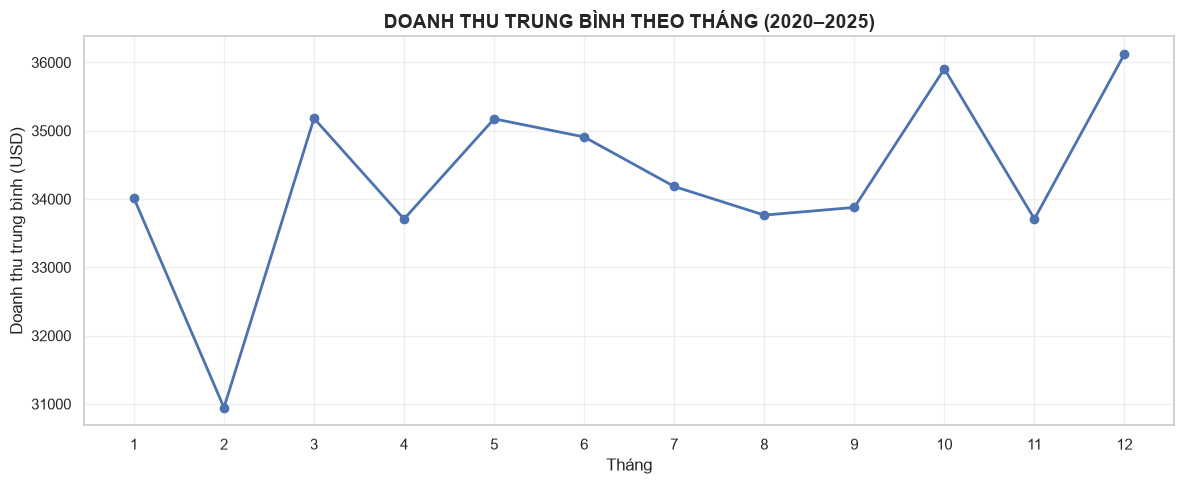

In [8]:
# Vẽ biểu đồ doanh thu trung bình theo tháng
plt.figure(figsize=(12, 5))

plt.plot(
    monthly_avg_revenue['Tháng'],
    monthly_avg_revenue['Doanh thu trung bình (USD)'],
    marker='o',
    linewidth=2
)

plt.title(
    'DOANH THU TRUNG BÌNH THEO THÁNG (2020–2025)',
    fontsize=14,
    fontweight='bold'
)
plt.xlabel('Tháng')
plt.ylabel('Doanh thu trung bình (USD)')
plt.xticks(range(1, 13))
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(
    '../report/monthly_revenue_seasonality.png',
    dpi=300,
    bbox_inches='tight'
)
plt.show()

### Nhận xét tính thời vụ

- Tháng 12 có doanh thu trung bình cao nhất, đạt 36.123,33 USD; tiếp theo là tháng 10 với 35.906,04 USD.
- Tháng 2 có doanh thu trung bình thấp nhất, đạt 30.946,73 USD, thấp hơn đáng kể so với các tháng còn lại.
- Các tháng 3, 5 và 6 cũng ghi nhận doanh thu trung bình tương đối cao.
- Doanh thu trung bình có sự khác biệt giữa các tháng, cho thấy dấu hiệu biến động theo mùa vụ. Đáng chú ý, doanh thu thường cao vào tháng 10 và tháng 12, trong khi tháng 2 có xu hướng thấp hơn.

### Kết luận

Doanh thu có dấu hiệu mang tính thời vụ, với mức doanh thu trung bình nổi bật vào cuối năm và thấp nhất vào tháng 2. Doanh nghiệp có thể cân nhắc tăng cường hoạt động kinh doanh và chuẩn bị nguồn hàng vào các giai đoạn có doanh thu cao, đồng thời triển khai chương trình kích cầu trong tháng có doanh thu thấp.